# Latent ODE Example

This notebook demonstrates using **LatentODE** for time series modeling with variational inference.

We will:
1. Generate synthetic spiral trajectory data
2. Train a Latent ODE model
3. Evaluate reconstruction quality

In [2]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from flax import nnx
import optax

import ldx

In [3]:
# Configuration
SEED = 42
N_SEQUENCES = 10
N_POINTS = 50
NOISE_STD = 0.1

LATENT_DIM = 4
HIDDEN_DIMS = (32, 32)
LEARNING_RATE = 1e-3
N_EPOCHS = 50
WARMUP_STEPS = 50

In [4]:
# Generate synthetic data - spiral trajectories
key = jax.random.PRNGKey(SEED)

batch_times, batch_observations = ldx.datasets.generate_spiral_trajectory(
    n_points=N_POINTS,
    n_sequences=N_SEQUENCES,
    n_dims=2,
    noise_std=NOISE_STD,
    key=key
)

print(f"Generated {N_SEQUENCES} sequences with {N_POINTS} time points each")
print(f"Observation shape: {batch_observations.shape}")

Generated 10 sequences with 50 time points each
Observation shape: (10, 50, 2)


In [5]:
# Normalize data and create train/val split
normalized_obs, norm_params = ldx.utils.normalize_data(batch_observations, method="standard")

(train_obs, train_times), (val_obs, val_times) = ldx.utils.create_train_val_split(
    normalized_obs, batch_times, val_fraction=0.3
)

obs_dim = batch_observations.shape[2]
print(f"Training: {train_obs.shape[0]} sequences, Validation: {val_obs.shape[0]} sequences")

Training: 7 sequences, Validation: 3 sequences


In [6]:
# Create model
key, model_key = jax.random.split(key)
rngs = nnx.Rngs(model_key)

model = ldx.models.create_latent_ode(
    latent_dim=LATENT_DIM,
    obs_dim=obs_dim,
    hidden_dims=HIDDEN_DIMS,
    dynamics_hidden_dims=HIDDEN_DIMS,
    encoder_type="mlp",
    decoder_type="mlp",
    rngs=rngs
)

print(f"Created LatentODE with latent_dim={LATENT_DIM}, obs_dim={obs_dim}")

Created LatentODE with latent_dim=4, obs_dim=2


In [7]:
# Setup training
optimizer = nnx.Optimizer(model, optax.adam(LEARNING_RATE), wrt=nnx.Param)

trainer = ldx.inference.VariationalTrainer(
    model=model,
    optimizer=optimizer,
    reconstruction_loss_fn=ldx.inference.reconstruction_loss_mse,
    beta_schedule=ldx.inference.create_beta_schedule("linear", warmup_steps=WARMUP_STEPS)
)

In [8]:
# Training loop
train_losses = []

for epoch in range(N_EPOCHS):
    key, train_key = jax.random.split(key)
    train_idx = jax.random.randint(train_key, (), 0, train_obs.shape[0])
    
    model, train_metrics = trainer.train_step(
        model, train_obs[train_idx], train_times[train_idx], train_key, epoch
    )
    train_losses.append(train_metrics["total_loss"])
    
    if epoch % 10 == 0:
        key, val_key = jax.random.split(key)
        val_idx = jax.random.randint(val_key, (), 0, val_obs.shape[0])
        val_metrics = trainer.evaluate(model, val_obs[val_idx], val_times[val_idx], val_key)
        print(f"Epoch {epoch:3d}: Train Loss = {train_metrics['total_loss']:.4f}, Val Loss = {val_metrics['total_loss']:.4f}")

print("Training completed!")

Epoch   0: Train Loss = 2.5436, Val Loss = 4.3333
Epoch  10: Train Loss = 1.0010, Val Loss = 3.3538
Epoch  20: Train Loss = 0.5956, Val Loss = 0.9026
Epoch  30: Train Loss = 0.9594, Val Loss = 0.7863
Epoch  40: Train Loss = 1.0277, Val Loss = 0.5754
Training completed!


In [9]:
# Generate predictions on validation sequence
key, pred_key = jax.random.split(key)

val_sequence = val_obs[0]
val_times_seq = val_times[0]

reconstructed_obs, _, _, _ = model(val_sequence[None, ...], val_times_seq[None, ...], pred_key)
reconstructed_obs = reconstructed_obs[0]

# Denormalize
reconstructed_denorm = ldx.utils.denormalize_data(reconstructed_obs, norm_params)
val_obs_denorm = ldx.utils.denormalize_data(val_sequence, norm_params)

while reconstructed_denorm.ndim > 2:
    reconstructed_denorm = reconstructed_denorm[0]
while val_obs_denorm.ndim > 2:
    val_obs_denorm = val_obs_denorm[0]

# Compute metrics
metrics = ldx.utils.compute_all_metrics(reconstructed_denorm, val_obs_denorm)
print("Evaluation Metrics:")
for name, value in metrics.items():
    print(f"  {name.upper()}: {value:.4f}")

Evaluation Metrics:
  MSE: 0.0390
  MAE: 0.1515
  RMSE: 0.1974
  MAPE: 2.6928
  R2: 0.8225
  CORRELATION: 0.9632


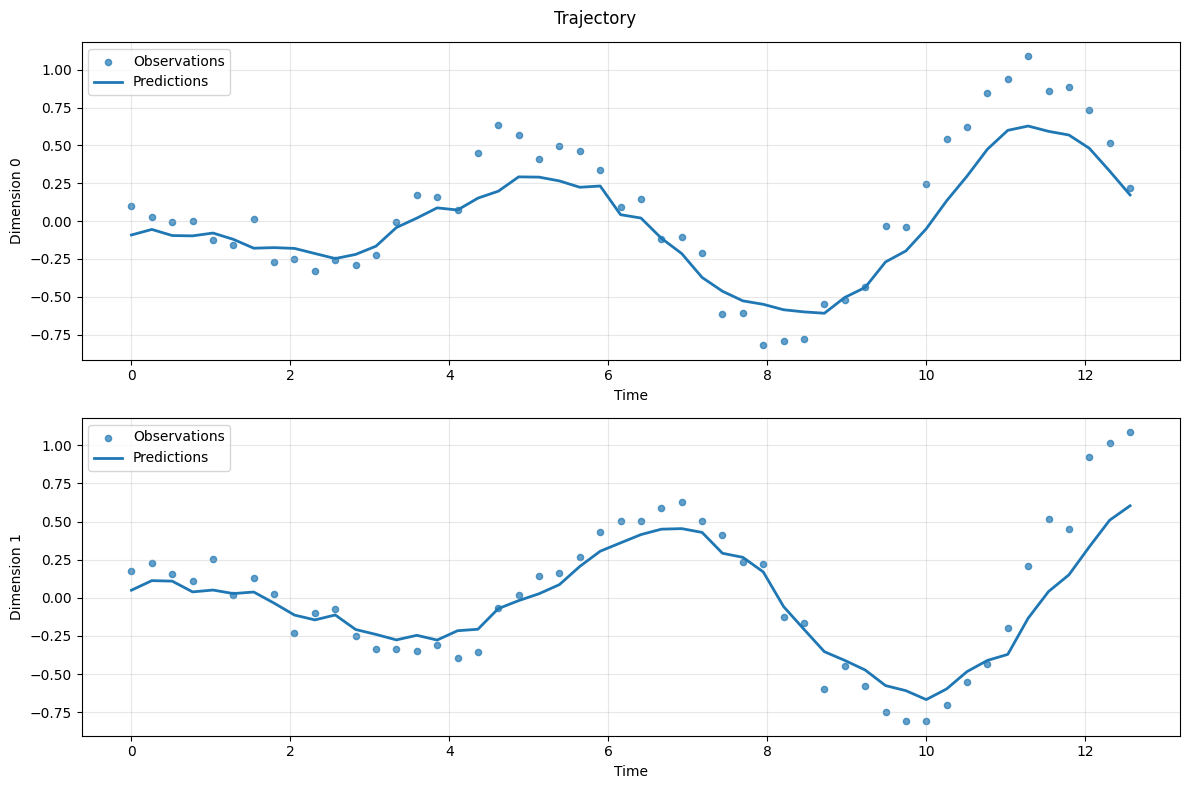

In [10]:
# Visualization - Trajectory Reconstruction
fig = ldx.utils.plot_trajectory(
    np.array(val_times_seq),
    np.array(val_obs_denorm),
    np.array(reconstructed_denorm),
    dims=[0, 1]
)
plt.show()